In [1]:
import numpy as np
import matplotlib.pyplot as plt
import opt_einsum
import torch

In [2]:
A = torch.tensor(np.load('A.npy'), dtype=torch.float32, device='cuda:0')[:1000]
# A = np.tile(A,(1,1,1))
# A = torch.randn((1000,200,200), dtype=torch.float32, device='cuda:0')
M = torch.tensor(np.load('M.npy'), dtype=torch.float32, device='cuda:0')
B = A@M
B = B[:,int(B.shape[1]/2):,int(B.shape[2]/2):]
rho_true = torch.tensor(torch.amax(torch.abs(torch.linalg.eigvals(B)), axis=-1), dtype=torch.float32, device='cuda:0').detach().cpu().numpy()

FileNotFoundError: [Errno 2] No such file or directory: 'A.npy'

In [43]:
x = torch.randn(B.shape[-1], dtype=torch.float32, device='cuda:0')
# x = torch.rand(B.shape[-1], dtype=torch.float32, device='cuda:0')
# x = x/torch.sqrt(torch.sum(x**2, axis=-1))

In [44]:
x.shape

torch.Size([100])

In [45]:
B.shape

torch.Size([1000, 100, 100])

In [46]:
rho_max = 0.99
tol = (1 - rho_max)/100
n_iterations = 10000

In [47]:
tol

0.00010000000000000009

In [48]:
def rho_max_power_iteration(B, x, tol, max_iterations, dtype, device):
    """
    Estimate the spectral radius (largest eigenvalue in magnitude) of a batch of matrices 
    using the power iteration method.

    Args:
    B : ndarray of shape (N, M, M)
        A batch of N symmetric square matrices of shape (M, M) whose spectral radii are to be estimated.
    x : ndarray of shape (M,)
        An initial guess for the eigenvector. This vector is tiled across the batch dimension.
    tol : float
        The convergence tolerance. Iteration continues until the maximum relative change in 
        spectral radius estimates across the batch falls below this threshold.

    Returns:
    rho : ndarray of shape (N,)
        The estimated spectral radii (largest eigenvalues) for each matrix in the batch.
    """
    #Add batch dimension to initial random vector
    x = torch.tile(x,(B.shape[0],1))
    reldiffs = torch.zeros((max_iterations, B.shape[0]), dtype=dtype, device=device)
    rhos = torch.zeros((max_iterations, B.shape[0]), dtype=dtype, device=device)
    #Initialize the relative difference and spectral radius estimate arrays
    reldiff = torch.ones(B.shape[0], dtype=dtype, device=device)
    rho = torch.ones(B.shape[0], dtype=dtype, device=device)
    i=0
    while torch.amax(reldiff)>tol and i<max_iterations:
        #Compute new spectral radius estimate
        Bx = opt_einsum.contract('Nij,Nj->Ni', B, x)
        xTBx = opt_einsum.contract('Ni,Ni->N', x, Bx)
        xTx = opt_einsum.contract('Ni,Ni->N', x, x)
        rho_new = xTBx/torch.max(xTx, 1e-7*torch.ones_like(xTx))
        #Compute absolute relative difference between estimate and previous estimate
        reldiff = torch.abs((rho_new - rho)/rho)
        reldiffs[i,:] = reldiff
        #Update spectral radius estimate
        rho = rho_new
        rhos[i,:] = rho_new
        #Update eigenvector estimate
        BxTBx = opt_einsum.contract('Ni,Ni->N', Bx, Bx)
        x = Bx/torch.max(BxTBx[:,None], 1e-7*torch.ones_like(BxTBx[:,None]))
        i+=1
    print(i)
    if i==max_iterations:
        print('Power iteration did not converge')
        rho = torch.ones(B.shape[0], dtype=dtype, device=device)
    # print(rho)
    v = x[0]
    return rho, v, rhos.detach().cpu().numpy(), reldiffs.detach().cpu().numpy()

In [49]:
rho, v, rhos, reldiffs = rho_max_power_iteration(B=B, x=x, tol=tol, max_iterations=1000, dtype=torch.float32, device='cuda:0')

102


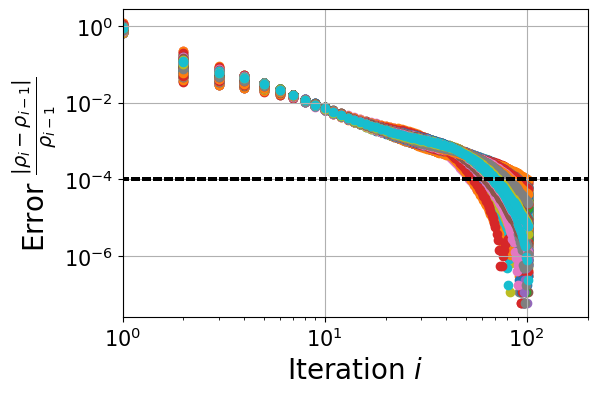

In [50]:
size_title = 20
size_ticklabels = 15
size_axeslabels = 20

fig, ax = plt.subplots(1,1, figsize=(6, 4))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=0.4)

plots = []
m=0
ax.tick_params(axis='both', labelsize=size_ticklabels)
# ax.scatter(np.arange(len(reldiffs.shape[0])),np.abs(rhos - rho_true)/rho_true, label =r'$|\rho_i - \rho_{\mathrm{true}}|/\rho_{\mathrm{true}}$')
for i in range(A.shape[0]):
    plt.scatter(np.arange(reldiffs.shape[0]),reldiffs[:,i], label=r'$|\rho_i - \rho_{i-1}|/\rho_{i-1}$')
ax.plot(np.arange(len(reldiffs)),np.ones_like(reldiffs)*tol, label='Tolerance', color='black', linestyle='--')
ax.set_xlabel(r'Iteration $i$', size=size_axeslabels)
ax.set_ylabel(r'Error $\frac{|\rho_i - \rho_{i-1}|}{\rho_{i-1}}$', size=size_axeslabels)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1,2e2)
# ax.legend(fontsize=10)
ax.grid()

plt.savefig("rhoi.png", bbox_inches='tight')#, transparent=True)

plt.show()

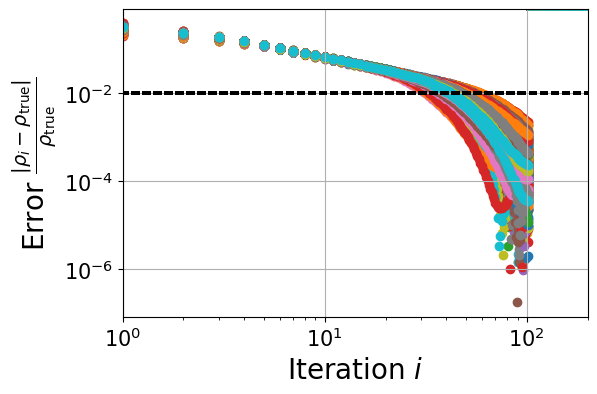

In [53]:
size_title = 20
size_ticklabels = 15
size_axeslabels = 20

fig, ax = plt.subplots(1,1, figsize=(6, 4))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=0.4)

plots = []
m=0
ax.tick_params(axis='both', labelsize=size_ticklabels)
# ax.scatter(np.arange(len(reldiffs.shape[0])),np.abs(rhos - rho_true)/rho_true, label =r'$|\rho_i - \rho_{\mathrm{true}}|/\rho_{\mathrm{true}}$')
for i in range(A.shape[0]):
    plt.scatter(np.arange(rhos.shape[0]),np.abs((rhos - rho_true)/rho_true)[:,i], label=r'$|\rho_i - \rho_{i-1}|/\rho_{i-1}$')
ax.plot(np.arange(len(reldiffs)),np.ones_like(reldiffs)*tol*100, label='Tolerance', color='black', linestyle='--')
ax.set_xscale('log')
ax.set_yscale('log')
# ax.legend(fontsize=10)
ax.set_xlabel(r'Iteration $i$', size=size_axeslabels)
ax.set_ylabel(r'Error $\frac{|\rho_i - \rho_{\mathrm{true}}|}{\rho_{\mathrm{true}}}$', size=size_axeslabels)
ax.grid()
ax.set_xlim(1,2e2)
ax.set_ylim(None,8e-1)
plt.savefig("rhotrue.png", bbox_inches='tight')#, transparent=True)

plt.show()